In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/nusratjahanmahi/crop-mapping/crop_mapping.csv
/kaggle/input/datasets/nusratjahanmahi/marker-2024-denmark/Marker_2024.cpg
/kaggle/input/datasets/nusratjahanmahi/marker-2024-denmark/Marker_2024.dbf
/kaggle/input/datasets/nusratjahanmahi/marker-2024-denmark/Marker_2024.prj
/kaggle/input/datasets/nusratjahanmahi/marker-2024-denmark/Marker_2024.shp
/kaggle/input/datasets/nusratjahanmahi/marker-2024-denmark/Marker_2024.shx
/kaggle/input/datasets/nusratjahanmahi/dagi-geojson/Kommuneinddeling_DAGI.geojson
/kaggle/input/datasets/nusratjahanmahi/pesticide-benchmarks/pesticide_benchmarks.csv
/kaggle/input/datasets/nusratjahanmahi/s2-features-final/s2_features_FINAL.csv


# Clustering Danish Farm Fields with Spark MLlib
**Thesis:** Exploratory clustering of Danish farm fields using satellite vegetation and moisture indicators
and crop-group pesticide benchmarks (Ringkøbing-Skjern, 2024).

## Task 0: Install, settings, imports and Spark


In [2]:
# Task 0: (cell 2): Install the libraries 

!pip install -q pyspark==3.5.3 earthengine-api pyogrio setuptools

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dataproc-spark-connect 1.1.0 requires pyspark[connect]~=4.0.0, but you have pyspark 3.5.3 which is incompatible.


In [3]:
# Task 0.1: (cell 3): Settings 
import os

# 1. Input files 
INPUT = "/kaggle/input/datasets/nusratjahanmahi"
MARKER_FILE = INPUT + "/marker-2024-denmark/Marker_2024.shp"                # all Danish farm fields 2024
BOUNDARY_FILE = INPUT + "/dagi-geojson/Kommuneinddeling_DAGI.geojson"      # official municipality borders (DAGI)
CROP_MAPPING_FILE = INPUT + "/crop-mapping/crop_mapping.csv"               # crop code -> crop group
PESTICIDE_FILE = INPUT + "/pesticide-benchmarks/pesticide_benchmarks.csv"  # pesticide numbers per crop group

# 2. Output file for satellite download 
SATELLITE_FILE = "data/s2_features.csv"

# 3. Check that every input file exists (must print True four times)
for path in [MARKER_FILE, BOUNDARY_FILE, CROP_MAPPING_FILE, PESTICIDE_FILE]:
    print(os.path.exists(path), path)

# 4. Study area and growing season
MUNICIPALITY_CODE = "0760"                   # Ringkøbing-Skjern
GEE_PROJECT = "majestic-bounty-508914-v6"    # Google Earth Engine project
SEASON_START = "2024-04-01"
SEASON_END = "2024-10-01"                    # this day is not included, so the season ends on 30 September
MONTHS = ["2024-04", "2024-05", "2024-06", "2024-07", "2024-08", "2024-09"]

# 5. Clustering settings
K_VALUES = [2, 3, 4, 5, 6]                   # numbers of clusters to try
SEEDS = [11, 22, 33]                         # three random starts, to test if the clusters are stable

# 6. The six candidate features
SATELLITE_FEATURES = ["ndvi_median", "ndvi_peak", "ndwi_median", "ndwi_at_peak"]
FEATURES = SATELLITE_FEATURES + ["bi_per_ha", "load_per_ha"]

# 7. Danish average treatment frequency for all farmland 2023/24 (Miljøstyrelsen 2026, Bilag 6)
NATIONAL_AVERAGE_BI = 3.99

True /kaggle/input/datasets/nusratjahanmahi/marker-2024-denmark/Marker_2024.shp
True /kaggle/input/datasets/nusratjahanmahi/dagi-geojson/Kommuneinddeling_DAGI.geojson
True /kaggle/input/datasets/nusratjahanmahi/crop-mapping/crop_mapping.csv
True /kaggle/input/datasets/nusratjahanmahi/pesticide-benchmarks/pesticide_benchmarks.csv


In [4]:
# Task 0.2: (cell 4): Import libraries
import sys                          # to tell Spark which Python to use
import json                         # to save the chosen settings at the end
import shutil                       #to copy the saved satellite file 
import numpy as np                  # numbers and arrays
import pandas as pd                 # tables
import geopandas as gpd             # tables with shapes (fields and borders)
import matplotlib.pyplot as plt     # charts
import seaborn as sns               # heatmap chart
import ee                           # Google Earth Engine

# Spark: session, column functions, machine learning
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, count, when, isnan
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans, BisectingKMeans
from pyspark.ml.evaluation import ClusteringEvaluator
from pyspark.ml.functions import vector_to_array

# scikit-learn: the scores that Spark does not have
from sklearn.metrics import davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score

# Folders for the results
os.makedirs("data/processed", exist_ok=True)
os.makedirs("results/figures", exist_ok=True)

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
# Task 0.3: (cell 5): Start a Spark session
# make Spark use the same Python as this notebook
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

# Arrow is off: Kaggle's Java does not support it with Spark 3.5 (it only changes speed, not results)
# shuffle.partitions = 8, because the data is small (Spark's default of 200 is for very big data)
spark = SparkSession.builder \
    .appName("FarmFieldClustering") \
    .config("spark.sql.execution.arrow.pyspark.enabled", "false") \
    .config("spark.sql.shuffle.partitions", "8") \
    .getOrCreate()

# hide Spark's long warning messages
spark.sparkContext.setLogLevel("ERROR")

# software versions (for Chapter 4 of the thesis)
print(f"Spark version: {spark.version}")
print(f"Python version: {sys.version.split()[0]}")
print(f"pandas version: {pd.__version__}")
print(f"geopandas version: {gpd.__version__}")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/09 18:32:33 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 3.5.3
Python version: 3.13.15
pandas version: 2.3.3
geopandas version: 1.1.4


## Task 1: Field data
Marker 2024 (Landbrugsstyrelsen) contains every registered farm field in Denmark with its crop code.
Fields are kept if a representative point inside the field lies within the official Ringkøbing-Skjern border
(DAGI, Klimadatastyrelsen), so that each border field is counted once. Fields without a crop code or smaller
than 0.5 ha are removed. Each field receives a stable identifier based on its row in the Marker file.
Farm identifiers (CVR and journal number) are not used.

In [6]:
# Task 1.1: (Cell 7): Load the municipality border
# read all Danish municipalities from the DAGI file
Municipalities = gpd.read_file(BOUNDARY_FILE)
print(f"Municipalities in the file: {len(Municipalities)}")

# keep only Ringkøbing-Skjern (code 0760)
MyMunicipality = Municipalities[Municipalities["kommunekode"] == MUNICIPALITY_CODE]

# change to metres (EPSG:25832), the same map system as Marker
MyMunicipality = MyMunicipality.to_crs("EPSG:25832")

print(f"Municipality: {MyMunicipality['navn'].iloc[0]}")
print(f"Area: {MyMunicipality.area.sum() / 1000000:.0f} km2")

Municipalities in the file: 99
Municipality: Ringkøbing-Skjern
Area: 1494 km2


In [7]:
# Task 1.2: (Cell 8): Load the Marker 2024 fields
# read only the fields inside the rectangle around the municipality 
area_box = tuple(MyMunicipality.total_bounds)
MarkerData = gpd.read_file(MARKER_FILE, bbox=area_box, fid_as_index=True, engine="pyogrio")
print(f"Fields in the rectangle: {len(MarkerData)}")

# keep the row number from the Marker file, it becomes the field ID later
MarkerData["marker_row"] = MarkerData.index

# keep only the columns need, with English names
# CVR and Journalnr identify the farm business, so they are left out (privacy)
MarkerData = MarkerData.rename(columns={"Afgkode": "crop_code", "Afgroede": "crop_name"})
MarkerData = MarkerData[["marker_row", "crop_code", "crop_name", "geometry"]]
MarkerData.head(10)

Fields in the rectangle: 31549


,marker_row,crop_code,crop_name,geometry
fid,,,,
8,8,1.0,Vårbyg,"POLYGON ((452655.045 6232704.307, 452746.591 6..."
109,109,31.0,Hestebønner,"POLYGON ((480393.497 6188618.544, 480369.014 6..."
713,713,342.0,Bestøverbrak,"POLYGON ((487361.399 6199438.519, 487372.053 6..."
714,714,342.0,Bestøverbrak,"POLYGON ((487463.653 6199210.09, 487454.777 61..."
814,814,527.0,Hassel (Corylus maxima),"POLYGON ((485144.32 6221208.1, 485116.51 62211..."
871,871,537.0,Valnød (almindelig),"POLYGON ((456747.879 6217452.785, 456738.639 6..."
872,872,537.0,Valnød (almindelig),"POLYGON ((456882.124 6217161.13, 456902.469 62..."
873,873,252.0,"Permanent græs, normalt udbytte","POLYGON ((459567.403 6183393.797, 459577.343 6..."
877,877,537.0,Valnød (almindelig),"POLYGON ((456742.023 6216855.448, 456740.88 62..."


In [8]:
# Task 1.3: (Cell 9): Keep only the fields inside Ringkøbing-Skjern
# make one point that is always inside each field
Points = MarkerData.copy()
Points["geometry"] = MarkerData.representative_point()

# keep the fields whose point is inside the municipality border
PointsInside = gpd.sjoin(Points, MyMunicipality[["geometry"]], predicate="within")
Fields = MarkerData.loc[PointsInside.index].copy()

print(f"Fields in the municipality: {len(Fields)}")

Fields in the municipality: 20084


In [9]:
# Task 1.4: (Cell 10): First cleaning of the fields
# remove fields with no crop code or no shape
Fields = Fields.dropna(subset=["crop_code", "geometry"])
Fields["crop_code"] = Fields["crop_code"].astype(int)

# field area in hectares (1 ha = 10,000 m2)
Fields["area_ha"] = Fields.area / 10000

# remove fields smaller than 0.5 ha (too few satellite pixels)
Fields = Fields[Fields["area_ha"] >= 0.5]

# field ID from the Marker row number, for example F001599 (it never changes)
Fields["field_id"] = "F" + Fields["marker_row"].astype(str).str.zfill(6)
Fields = Fields.drop(columns="marker_row").reset_index(drop=True)

print(f"Fields after cleaning: {len(Fields)}")

Fields after cleaning: 17476


crop_name
Vårbyg                                                   23440.0
Græs med kløver/lucerne, under 50 % bælgpl. (omdrift)     8228.0
Silomajs                                                  7125.0
Vinterhvede                                               6442.0
Silomajs med græsudlæg                                    4057.0
Brak, slåning                                             4052.0
Kartofler, stivelses-                                     3993.0
Miljøgræs MVJ-tilsagn (0 N), permanent                    3371.0
Vinterraps                                                2919.0
Vinterhybridrug                                           2480.0
Name: area_ha, dtype: float64


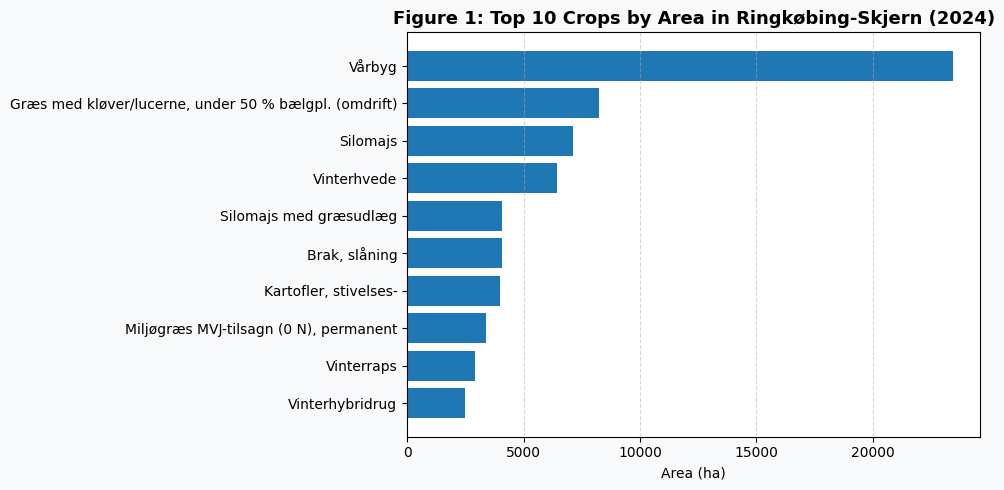

In [10]:
# Task 1.5: (Cell 11): Figure 1 - the 10 biggest crops by area
TopCrops = Fields.groupby("crop_name")["area_ha"].sum().sort_values(ascending=False).head(10)
print(TopCrops.round(0))

plt.figure(figsize=(10, 5), facecolor="#f8f9fa")
plt.barh(TopCrops.index[::-1], TopCrops.values[::-1], color="#1f77b4")
plt.title("Figure 1: Top 10 Crops by Area in Ringkøbing-Skjern (2024)", fontsize=13, fontweight="bold")
plt.xlabel("Area (ha)")
plt.grid(True, axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("results/figures/fig1_top_crops.png", dpi=200)
plt.show()

## Task 2: Satellite indicators
Two indices are calculated from Sentinel-2 surface-reflectance images (1 April to 30 September 2024, under 60% cloud):
* **NDVI** = (B8 − B4) / (B8 + B4), an indicator of green vegetation
* **NDWI** = (B8 − B11) / (B8 + B11), an indicator of leaf water content (Gao, 1996); lower values indicate drier vegetation

Remaining clouds are masked with Cloud Score+ (pixels with a score below 0.6 are excluded). Fields are shrunk by 10 m
to avoid mixed edge pixels. For each field, the season median and a median for each month are calculated.

The driest month often shows bare soil before sowing or after harvest rather than a dry crop. Moisture is therefore
measured as NDWI in each field's greenest month (`ndwi_at_peak`); the driest-month NDWI (`ndwi_min`) is kept only
for comparison (Task 5).

In [11]:
# Task 2.1: (Cell 13): Log in to Google Earth Engine
# satellite file from the original Earth Engine extraction (Sentinel-2, 1 April to 30 September 2024)
# and uploaded as a Kaggle dataset, so the notebook can run again without logging in
SAVED_SATELLITE_FILE = "/kaggle/input/datasets/nusratjahanmahi/s2-features-final/s2_features_FINAL.csv"

if not os.path.exists(SATELLITE_FILE) and os.path.exists(SAVED_SATELLITE_FILE):
    shutil.copy(SAVED_SATELLITE_FILE, SATELLITE_FILE)
    print("Using my saved satellite file")

# only needed if the satellite file does not exist yet
NEED_DOWNLOAD = not os.path.exists(SATELLITE_FILE)

if NEED_DOWNLOAD:
    # shows a link: open it, log in with a Google account, copy the code and paste it in the box
    ee.Authenticate(auth_mode="notebook")
    ee.Initialize(project=GEE_PROJECT)
    print("Earth Engine is ready")
else:
    print("Satellite file already exists - download is skipped")

Using my saved satellite file
Satellite file already exists - download is skipped


In [12]:
# Task 2.2: (Cell 14): Prepare the fields for Earth Engine
if NEED_DOWNLOAD:
    FieldsLatLon = Fields[["field_id", "geometry"]].copy()

    # shrink every field by 10 m, so roads, hedges and edge pixels are not counted
    # simplify the shape (5 m) so it is faster to send to Earth Engine
    FieldsLatLon["geometry"] = FieldsLatLon.buffer(-10).simplify(5)

    # very thin fields disappear after shrinking, so they are removed
    FieldsLatLon = FieldsLatLon[~FieldsLatLon.is_empty]

    # Earth Engine needs latitude/longitude (EPSG:4326)
    FieldsLatLon = FieldsLatLon.to_crs("EPSG:4326")
    print(f"Fields sent to Earth Engine: {len(FieldsLatLon)} (lost by the 10 m shrink: {len(Fields) - len(FieldsLatLon)})")

In [13]:
# Task 2.3: (Cell 15): Choose the satellite images and calculate NDVI and NDWI
if NEED_DOWNLOAD:

    # for one image: hide clouds, then calculate NDVI and NDWI
    def make_ndvi_and_ndwi(image):
        image = image.updateMask(image.select("cs").gte(0.6))              # Cloud Score+: keep clear pixels only
        ndvi = image.normalizedDifference(["B8", "B4"]).rename("ndvi")      # (B8 - B4) / (B8 + B4)
        ndwi = image.normalizedDifference(["B8", "B11"]).rename("ndwi")     # (B8 - B11) / (B8 + B11)
        both = ndvi.addBands(ndwi)
        return ee.Image(both.copyProperties(image, ["system:time_start"]))  # keep the date of the image

    # the rectangle around all study fields
    StudyBox = ee.Geometry.Rectangle(list(FieldsLatLon.total_bounds))

    # Sentinel-2 surface reflectance + the Cloud Score+ layer for every image
    CloudScore = ee.ImageCollection("GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED")
    Images = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED") \
        .filterBounds(StudyBox) \
        .filterDate(SEASON_START, SEASON_END) \
        .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 60)) \
        .linkCollection(CloudScore, ["cs"]) \
        .map(make_ndvi_and_ndwi)

    print(f"Sentinel-2 images used: {Images.size().getInfo()}")

In [14]:
# Task 2.4: (Cell 16): Make one image with the season median and one median per month
if NEED_DOWNLOAD:
    # layer 1-2: median of the whole season
    Layers = [Images.median().rename(["ndvi_season", "ndwi_season"])]

    # layers 3-14: median of every month (April to September)
    for month in MONTHS:
        start = ee.Date(month + "-01")
        end = start.advance(1, "month")
        name = month.replace("-", "_")
        Layers.append(Images.filterDate(start, end).median().rename(["ndvi_" + name, "ndwi_" + name]))

    BigImage = ee.Image.cat(Layers)
    print(f"Layers in the image: {len(BigImage.bandNames().getInfo())}")

In [15]:
# Task 2.5: (Cell 17): Average of every layer inside every field (500 fields at a time)
# each batch is saved, so an interrupted run continues from the last saved batch
if NEED_DOWNLOAD:
    os.makedirs("data/satellite_parts", exist_ok=True)

    # mean = average value in the field, count = number of clear pixels
    MeanAndCount = ee.Reducer.mean().combine(ee.Reducer.count(), sharedInputs=True)

    # Earth Engine sends back only the numbers, not the field shapes
    def drop_shape(feature):
        return ee.Feature(None, feature.toDictionary())

    for start in range(0, len(FieldsLatLon), 500):
        part_file = f"data/satellite_parts/part_{start}.csv"
        if os.path.exists(part_file):
            continue                                       # this batch is already done
        Batch = FieldsLatLon.iloc[start:start + 500]
        Result = BigImage.reduceRegions(collection=ee.FeatureCollection(Batch.__geo_interface__),
                                        reducer=MeanAndCount, scale=10, tileScale=4)
        rows = [f["properties"] for f in Result.map(drop_shape).getInfo()["features"]]
        pd.DataFrame(rows).to_csv(part_file, index=False)
        print(f"Done: {min(start + 500, len(FieldsLatLon))} of {len(FieldsLatLon)}")

In [16]:
# Task 2.6: (Cell 18): Join all batches into one table and save it
if NEED_DOWNLOAD:
    Raw = pd.concat([pd.read_csv("data/satellite_parts/" + name) for name in os.listdir("data/satellite_parts")])

    S2 = pd.DataFrame()
    S2["field_id"] = Raw["field_id"]
    S2["valid_pixels"] = Raw["ndvi_season_count"]          # clear pixels in the field
    S2["ndvi_median"] = Raw["ndvi_season_mean"]
    S2["ndwi_median"] = Raw["ndwi_season_mean"]
    for month in MONTHS:
        name = month.replace("-", "_")
        S2["ndvi_" + name] = Raw["ndvi_" + name + "_mean"]
        S2["ndwi_" + name] = Raw["ndwi_" + name + "_mean"]

    S2.to_csv(SATELLITE_FILE, index=False)
    print(f"Saved {SATELLITE_FILE} with {len(S2)} fields")

In [17]:
# Task 2.7: (Cell 19): Make the four satellite features
S2 = pd.read_csv(SATELLITE_FILE)
ndvi_months = ["ndvi_" + month.replace("-", "_") for month in MONTHS]
ndwi_months = ["ndwi_" + month.replace("-", "_") for month in MONTHS]

# peak NDVI = the greenest month
S2["ndvi_peak"] = S2[ndvi_months].max(axis=1)

# driest-month NDWI, kept only for comparison (often a bare field, not a dry crop)
S2["ndwi_min"] = S2[ndwi_months].min(axis=1)

# which month was the greenest for each field (fields with no clear month get none)
has_ndvi = S2[ndvi_months].notna().any(axis=1)
S2["peak_month"] = None
S2.loc[has_ndvi, "peak_month"] = S2.loc[has_ndvi, ndvi_months].idxmax(axis=1).str.replace("ndvi_", "")

# NDWI in the greenest month = moisture of the crop when it is fully grown
S2["ndwi_at_peak"] = [S2.at[i, "ndwi_" + m] if m else np.nan for i, m in S2["peak_month"].items()]

S2[["ndvi_median", "ndvi_peak", "ndwi_median", "ndwi_at_peak", "ndwi_min", "valid_pixels"]].describe().round(3)

,ndvi_median,ndvi_peak,ndwi_median,ndwi_at_peak,ndwi_min,valid_pixels
count,17390.000,17390.000,17390.000,17390.000,17390.000,17391.000
mean,0.661,0.839,0.191,0.403,-0.024,849.908
std,0.162,0.068,0.159,0.101,0.198,1073.344
min,-0.011,0.016,-0.505,-0.506,-0.575,0.000
25%,0.543,0.808,0.066,0.347,-0.214,203.500
50%,0.701,0.853,0.218,0.415,-0.039,495.000
75%,0.791,0.888,0.314,0.473,0.155,1120.500
max,0.923,0.951,0.593,0.664,0.518,44026.000


## Task 3: Crop groups and pesticide benchmarks
Each of the 119 Marker crop codes in the study area is linked to one crop category of the national pesticide
statistics (`crop_mapping.csv`, matched by hand; uncertain matches are marked for review). For each crop group,
the treatment frequency (BI/ha) and pesticide load (B/ha) are taken from Miljøstyrelsen (2026), *Bekæmpelsesmiddelstatistik
2024*, Bilag 6, p. 126, based on farmers' spray records from 1 August 2023 to 31 July 2024.

These values are national averages per crop group. Every field of the same crop group therefore receives the same
pesticide values, which limits how far the clusters can be read as field-level pesticide use.

In [18]:
# Task 3.1: (cell 21): Load the crop mapping and the pesticide numbers
# crop mapping: every Marker crop code -> one crop group of the pesticide report
CropMapping = pd.read_csv(CROP_MAPPING_FILE, encoding="utf-8-sig")[["crop_code", "crop_group"]]

# pesticide numbers per crop group (Miljøstyrelsen 2026, Bilag 6, page 126)
Pesticide = pd.read_csv(PESTICIDE_FILE)[["crop_group", "bi_per_ha", "load_per_ha"]]

print(f"Crop codes in the mapping: {len(CropMapping)}")
print(f"Crop groups in the pesticide table: {len(Pesticide)}")
Pesticide

Crop codes in the mapping: 119
Crop groups in the pesticide table: 17


,crop_group,bi_per_ha,load_per_ha
0,winter_cereals,3.97,2.46
1,spring_cereals,2.66,0.83
2,rapeseed,4.43,2.81
3,grass_seed,3.71,1.89
4,potatoes,22.82,8.17
5,sugar_beet,4.76,3.05
6,other_beet,4.76,3.05
7,pulses,2.51,3.01
8,maize,1.61,0.65
9,vegetables,4.66,5.40


## Task 4: Data integration and cleaning in Spark
The field, satellite, crop-group and pesticide tables are combined with left joins on `field_id`, `crop_code` and
`crop_group`, so that every field is retained and missing values become visible. Fields are then removed step by step.

Missing values are removed rather than imputed. Imputing a satellite value would create a reading that was never
observed, and imputing a pesticide value would assign a crop a benchmark that the national statistics do not provide.

In [19]:
# Task 4.1: (cell 23): Load the four tables into Spark and join them
# the field shapes are not needed in Spark, so the geometry column is left out
FieldsData = spark.createDataFrame(pd.DataFrame(Fields.drop(columns="geometry")))
SatelliteData = spark.createDataFrame(S2)
MappingData = spark.createDataFrame(CropMapping)
PesticideData = spark.createDataFrame(Pesticide)

# left join = keep every field, even if it has no satellite values or pesticide numbers
JoinedData = FieldsData \
    .join(SatelliteData, on="field_id", how="left") \
    .join(MappingData, on="crop_code", how="left") \
    .join(PesticideData, on="crop_group", how="left")

print(f"Rows after joining: {JoinedData.count()}")

/usr/local/lib/python3.13/dist-packages/pyspark/sql/pandas/conversion.py:351: UserWarning: createDataFrame attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  sun.misc.Unsafe or java.nio.DirectByteBuffer.<init>(long, int) not available
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


Rows after joining: 17476


In [20]:
# Task 4.2: (cell 24): Count the missing values in each column BEFORE cleaning
NumberColumns = ["valid_pixels"] + FEATURES

print(f"Fields with no crop group: {JoinedData.filter(col('crop_group').isNull()).count()}")

# a value is missing if it is null or NaN (not a number)
JoinedData.select([
    count(when(col(c).isNull() | isnan(col(c)), c)).alias(c)
    for c in NumberColumns
]).show()

Fields with no crop group: 0
+------------+-----------+---------+-----------+------------+---------+-----------+
|valid_pixels|ndvi_median|ndvi_peak|ndwi_median|ndwi_at_peak|bi_per_ha|load_per_ha|
+------------+-----------+---------+-----------+------------+---------+-----------+
|          85|         86|       86|         86|          86|     3911|       3911|
+------------+-----------+---------+-----------+------------+---------+-----------+



In [21]:
# Task 4.3: (cell 25): Cleaning - count the fields after every step (this table goes in Chapter 4)
CleaningLog = []
CleaningLog.append(["1. Fields in the municipality", JoinedData.count()])

# step 2: enough clear satellite pixels
CleanData = JoinedData.dropna(subset=["valid_pixels"])
CleanData = CleanData.filter(col("valid_pixels") >= 10)
CleaningLog.append(["2. At least 10 cloud-free pixels", CleanData.count()])

# step 3: the crop code has a crop group
CleanData = CleanData.dropna(subset=["crop_group"])
CleaningLog.append(["3. Crop code has a crop group", CleanData.count()])

# step 4: the crop group has pesticide numbers in the report
CleanData = CleanData.dropna(subset=["bi_per_ha", "load_per_ha"])
CleaningLog.append(["4. Crop group has pesticide numbers", CleanData.count()])

# step 5: all four satellite values exist and are between -1 and 1
CleanData = CleanData.dropna(subset=SATELLITE_FEATURES)
for feature in SATELLITE_FEATURES:
    CleanData = CleanData.filter((col(feature) >= -1) & (col(feature) <= 1))
CleaningLog.append(["5. All satellite values present and valid", CleanData.count()])

# step 6: no field twice
CleanData = CleanData.dropDuplicates(["field_id"]).cache()
CleaningLog.append(["6. Final (no duplicates)", CleanData.count()])

CleaningLog = pd.DataFrame(CleaningLog, columns=["Step", "Fields"])
CleaningLog.to_csv("results/cleaning_log.csv", index=False)
CleaningLog

,Step,Fields
0,1. Fields in the municipality,17476
1,2. At least 10 cloud-free pixels,17369
2,3. Crop code has a crop group,17369
3,4. Crop group has pesticide numbers,13510
4,5. All satellite values present and valid,13510
5,6. Final (no duplicates),13510


In [22]:
# Task 4.4: (cell 26): Which crop groups were left out because the report has no pesticide numbers? (Spark SQL)
LeftOut = JoinedData.filter(col("crop_group").isNotNull() & (col("bi_per_ha").isNull() | isnan(col("bi_per_ha"))))
LeftOut.createOrReplaceTempView("tbl_LeftOut")

spark.sql("""
SELECT crop_group,
  COUNT(*) AS Fields,
  ROUND(SUM(area_ha), 0) AS Area_ha
FROM tbl_LeftOut
GROUP BY crop_group
ORDER BY Area_ha DESC
""").show()

# share of the field area that stays in the study
all_area = JoinedData.groupBy().sum("area_ha").collect()[0][0]
kept_area = CleanData.groupBy().sum("area_ha").collect()[0][0]
print(f"Share of the field area kept in the study: {100 * kept_area / all_area:.1f}%")

+------------------+------+-------+
|        crop_group|Fields|Area_ha|
+------------------+------+-------+
|         set_aside|  2454| 5725.0|
|forest_other_woody|   917| 2773.0|
|    other_non_crop|   360| 1623.0|
|   christmas_trees|   116|  241.0|
|     fruit_berries|    64|  189.0|
+------------------+------+-------+

Share of the field area kept in the study: 88.7%


## Task 5: Exploratory data analysis
Before clustering, the data are examined in five steps: summary statistics per crop group, the seasonal pattern of
NDVI and NDWI, a check of whether the driest month reflects a dry crop or bare soil, outliers (IQR rule), and the
correlation between the candidate features. The results inform two decisions made before clustering: whether to keep
outliers and which correlated features to remove.



In [23]:
# Task 5.1: (Cell 28): Summary by crop group (Spark SQL)
CleanData.createOrReplaceTempView("tbl_CleanData")

cropSummary = spark.sql("""
SELECT crop_group,
  COUNT(*) AS Fields,
  ROUND(SUM(area_ha), 0) AS Area_ha,
  ROUND(AVG(ndvi_peak), 3) AS Avg_Peak_NDVI,
  ROUND(AVG(ndwi_at_peak), 3) AS Avg_NDWI_at_Peak,
  ROUND(AVG(ndwi_min), 3) AS Avg_Driest_NDWI,
  ROUND(AVG(bi_per_ha), 2) AS BI_per_ha
FROM tbl_CleanData
GROUP BY crop_group
ORDER BY Area_ha DESC
""")
cropSummary.show(truncate=False)

+---------------------+------+-------+-------------+----------------+---------------+---------+
|crop_group           |Fields|Area_ha|Avg_Peak_NDVI|Avg_NDWI_at_Peak|Avg_Driest_NDWI|BI_per_ha|
+---------------------+------+-------+-------------+----------------+---------------+---------+
|spring_cereals       |3936  |27759.0|0.856        |0.45            |-0.202         |2.66     |
|grass_clover_rotation|2520  |13306.0|0.864        |0.408           |0.173          |0.02     |
|maize                |1624  |12056.0|0.838        |0.388           |-0.233         |1.61     |
|winter_cereals       |1378  |9982.0 |0.811        |0.386           |-0.108         |3.97     |
|permanent_grass      |2523  |7757.0 |0.842        |0.382           |0.16           |0.02     |
|potatoes             |628   |5393.0 |0.882        |0.448           |-0.254         |22.82    |
|rapeseed             |390   |2926.0 |0.822        |0.531           |-0.173         |4.43     |
|grass_seed           |264   |2451.0 |0.

In [24]:
# Task 5.0: (Cell 29): Turn off Arrow - Kaggle's Java does not support it with Spark 3.5
spark.conf.set("spark.sql.execution.arrow.pyspark.enabled", "false")
print(f"Arrow enabled: {spark.conf.get('spark.sql.execution.arrow.pyspark.enabled')}")

Arrow enabled: false


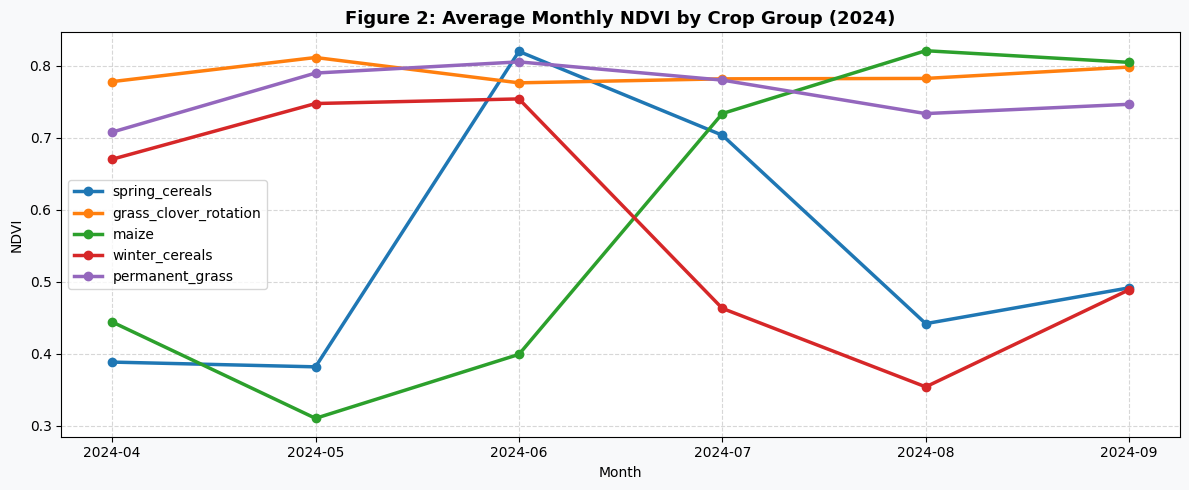

In [25]:
# Task 5.2: (Cell 30): Figure 2 - average NDVI per month for the 5 biggest crop groups
# copy the clean data to pandas for the charts (13,510 rows is small)
CleanPd = CleanData.toPandas()
TopGroups = CleanPd.groupby("crop_group")["area_ha"].sum().sort_values(ascending=False).head(5).index
colours = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]

plt.figure(figsize=(12, 5), facecolor="#f8f9fa")
for group, colour in zip(TopGroups, colours):
    monthly_ndvi = CleanPd[CleanPd["crop_group"] == group][ndvi_months].mean()
    plt.plot(MONTHS, monthly_ndvi.values, marker="o", color=colour, linewidth=2.5, label=group)

plt.title("Figure 2: Average Monthly NDVI by Crop Group (2024)", fontsize=13, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("NDVI")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("results/figures/fig2_monthly_ndvi.png", dpi=200)
plt.show()

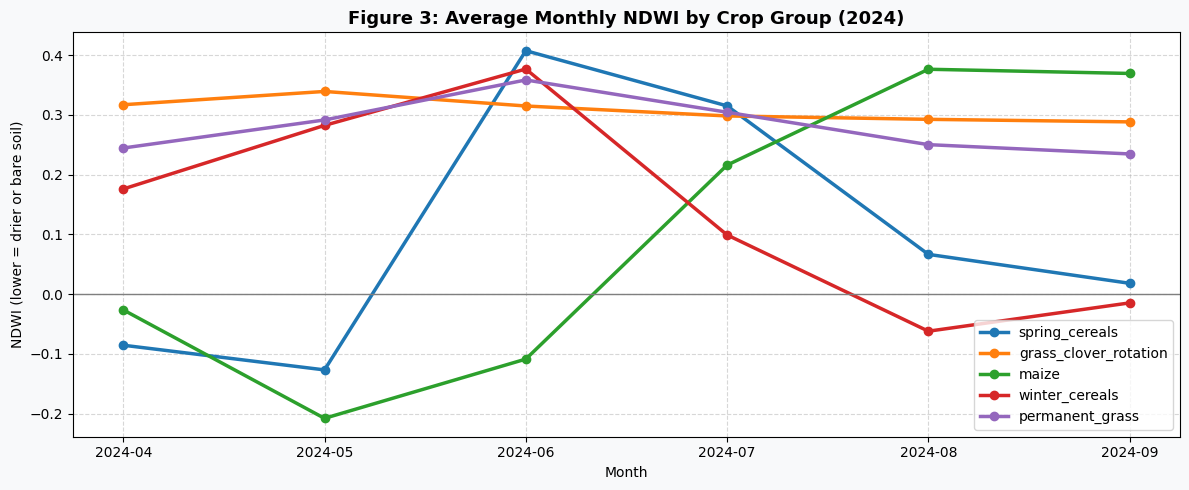

In [26]:
# Task 5.3: (Cell 31): Figure 3 - average NDWI per month for the same 5 crop groups
plt.figure(figsize=(12, 5), facecolor="#f8f9fa")
for group, colour in zip(TopGroups, colours):
    monthly_ndwi = CleanPd[CleanPd["crop_group"] == group][ndwi_months].mean()
    plt.plot(MONTHS, monthly_ndwi.values, marker="o", color=colour, linewidth=2.5, label=group)

plt.axhline(0, color="#7f7f7f", linewidth=1)
plt.title("Figure 3: Average Monthly NDWI by Crop Group (2024)", fontsize=13, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("NDWI (lower = drier or bare soil)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("results/figures/fig3_monthly_ndwi.png", dpi=200)
plt.show()

In [27]:
# Task 5.4: (Cell 32): Bare-soil check - is the driest month a dry crop, or a bare field?
# the driest month = the month with the lowest NDWI
CleanPd["driest_month"] = CleanPd[ndwi_months].idxmin(axis=1).str.replace("ndwi_", "")

# for each crop group: the most common greenest month and driest month
BareSoilCheck = CleanPd.groupby("crop_group").agg(
    Fields=("field_id", "count"),
    Greenest_month=("peak_month", lambda months: months.mode()[0]),
    Driest_month=("driest_month", lambda months: months.mode()[0]),
    Avg_NDWI_at_peak=("ndwi_at_peak", "mean"),
    Avg_Driest_NDWI=("ndwi_min", "mean"),
).sort_values("Fields", ascending=False)

BareSoilCheck.to_csv("results/bare_soil_check.csv")
BareSoilCheck.round(3)

,Fields,Greenest_month,Driest_month,Avg_NDWI_at_peak,Avg_Driest_NDWI
crop_group,,,,,
spring_cereals,3936,2024_06,2024_05,0.450,-0.202
permanent_grass,2523,2024_06,2024_09,0.382,0.160
grass_clover_rotation,2520,2024_05,2024_07,0.408,0.173
maize,1624,2024_08,2024_05,0.388,-0.233
winter_cereals,1378,2024_06,2024_08,0.386,-0.108
potatoes,628,2024_07,2024_05,0.448,-0.254
rapeseed,390,2024_04,2024_09,0.531,-0.173
grass_seed,264,2024_05,2024_08,0.480,0.036
pulses,207,2024_06,2024_05,0.501,-0.209


In [28]:
# Task 5.5: (Cell 33): Summary statistics of the six candidate features
CleanPd[FEATURES].describe().round(3)

,ndvi_median,ndvi_peak,ndwi_median,ndwi_at_peak,bi_per_ha,load_per_ha
count,13510.000,13510.000,13510.000,13510.000,13510.000,13510.000
mean,0.641,0.849,0.173,0.419,2.695,1.132
std,0.170,0.061,0.166,0.093,4.683,1.778
min,0.195,0.288,-0.505,-0.506,0.020,0.020
25%,0.503,0.821,0.035,0.366,0.020,0.020
50%,0.667,0.861,0.191,0.427,2.510,0.830
75%,0.788,0.893,0.309,0.483,2.660,0.830
max,0.923,0.951,0.576,0.659,22.820,8.170


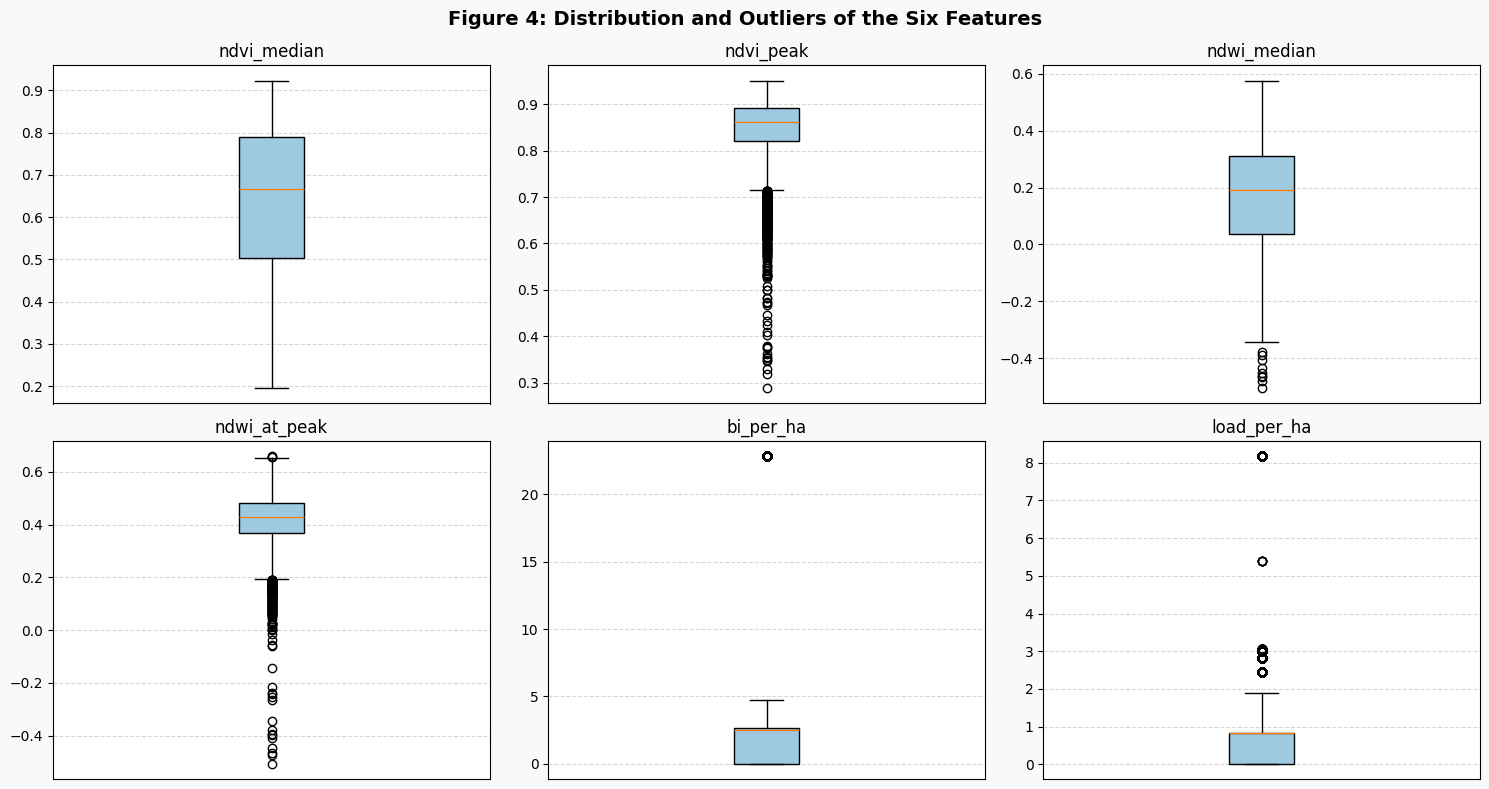

In [29]:
# Task 5.6: (Cell 34): Figure 4-boxplots to look for outliers
fig, axes = plt.subplots(2, 3, figsize=(15, 8), facecolor="#f8f9fa")
for ax, feature in zip(axes.flatten(), FEATURES):
    ax.boxplot(CleanPd[feature], patch_artist=True, boxprops=dict(facecolor="#9ecae1"))
    ax.set_title(feature)
    ax.set_xticks([])
    ax.grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Figure 4: Distribution and Outliers of the Six Features", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("results/figures/fig4_boxplots.png", dpi=200)
plt.show()

In [30]:
# Task 5.7: (Cell 35): Count the outliers with the IQR rule
# outlier = below Q1 - 1.5*IQR or above Q3 + 1.5*IQR
OutlierRows = []
for feature in FEATURES:
    q1 = CleanPd[feature].quantile(0.25)
    q3 = CleanPd[feature].quantile(0.75)
    iqr = q3 - q1
    is_outlier = (CleanPd[feature] < q1 - 1.5 * iqr) | (CleanPd[feature] > q3 + 1.5 * iqr)
    OutlierRows.append([feature, is_outlier.sum(), round(100 * is_outlier.mean(), 1)])

OutlierTable = pd.DataFrame(OutlierRows, columns=["Feature", "Outliers", "Percent"])
OutlierTable.to_csv("results/outliers.csv", index=False)
OutlierTable

,Feature,Outliers,Percent
0,ndvi_median,0,0.0
1,ndvi_peak,412,3.0
2,ndwi_median,9,0.1
3,ndwi_at_peak,219,1.6
4,bi_per_ha,628,4.6
5,load_per_ha,2643,19.6


**Decision**: outliers. The satellite values were already checked (clouds removed, all values between −1 and 1),
so extreme values are real fields. The pesticide "outliers" are mostly potato fields, whose treatment frequency really is
much higher. Removing them would delete exactly the fields the study wants to find. K-means is sensitive to outliers,
so this is checked with the stability test and the cluster-size check in Task 8.

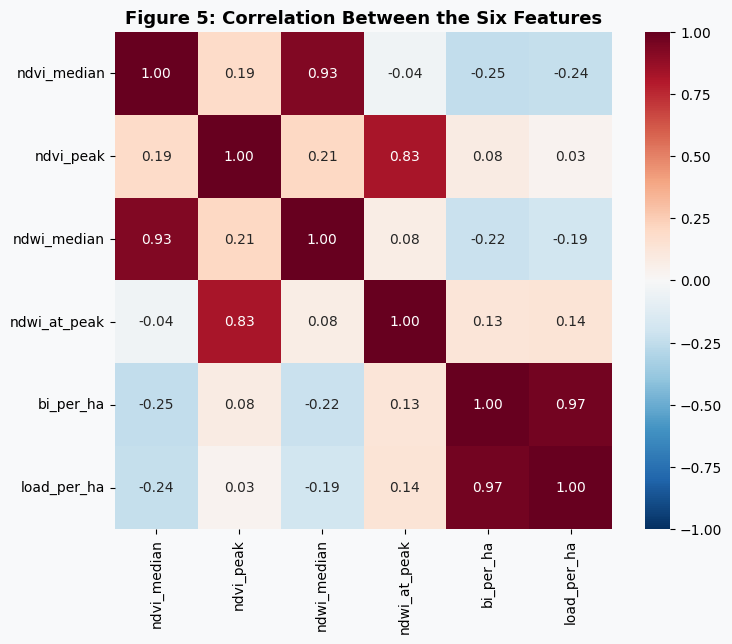

In [31]:
# Task 5.8: (Cell 37): Figure 5 - correlation between the six features
Correlation = CleanPd[FEATURES].corr()

plt.figure(figsize=(8, 6.5), facecolor="#f8f9fa")
sns.heatmap(Correlation, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Figure 5: Correlation Between the Six Features", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("results/figures/fig5_correlation.png", dpi=200)
plt.show()

**Correlation rule:** if two features have a correlation of 0.95 or more, they carry almost
the same information, so only one of them is used for clustering. For each pair I keep the first one:
treatment frequency (main pesticide measure), NDWI at peak (moisture of the grown crop) and peak NDVI (crop vigour).

In [32]:
# Task 5.9: (Cell 39): Apply the correlation rule
CLUSTER_FEATURES = FEATURES.copy()
pairs = [("bi_per_ha", "load_per_ha"), ("ndwi_at_peak", "ndwi_median"), ("ndvi_peak", "ndvi_median")]

for keep, drop in pairs:
    r = Correlation.loc[keep, drop]
    print(f"{keep} vs {drop}: r = {r:.2f}")
    if abs(r) >= 0.95:
        CLUSTER_FEATURES.remove(drop)
        print(f"   -> too similar, so {drop} is not used for clustering")

print(f"\nFeatures used for clustering: {CLUSTER_FEATURES}")

bi_per_ha vs load_per_ha: r = 0.97
   -> too similar, so load_per_ha is not used for clustering
ndwi_at_peak vs ndwi_median: r = 0.08
ndvi_peak vs ndvi_median: r = 0.19

Features used for clustering: ['ndvi_median', 'ndvi_peak', 'ndwi_median', 'ndwi_at_peak', 'bi_per_ha']


## Task 6: Prepare the features ##
The features have different units, so each one is divided by its standard deviation (`StandardScaler`).
Otherwise the feature with the biggest numbers would control the clustering.

**Why `withMean=False`:** Spark's Bisecting K-means splits a cluster by moving its centre a little. If the data were
centred at zero, the first centre would be exactly zero, it could not move, and the algorithm would return only one cluster.
Moving all points by the same amount does not change any distance, so the results are not affected.

**Reproducibility:** K-means chooses its random starting points per data partition, so the result can change with the number
of CPU cores. The data is therefore sorted by field ID and kept in one partition, so every computer gets the same result
(tested with 2, 4 and 12 cores). At 13,510 fields this costs no noticeable time.

In [33]:
# Task 6.1: (Cell 41): Put the features into one vector and scale them
# 1. put the 5 clustering features into one column called raw_features
assembler = VectorAssembler(inputCols=CLUSTER_FEATURES, outputCol="raw_features")

# 2. divide every feature by its standard deviation (withMean=False, see the text above)
scaler = StandardScaler(inputCol="raw_features", outputCol="features", withMean=False, withStd=True)

Assembled = assembler.transform(CleanData)
ModelData = scaler.fit(Assembled).transform(Assembled).select("field_id", "crop_group", "features")

# 3. same order and one partition on every computer, so the results can be repeated
ModelData = ModelData.orderBy("field_id").coalesce(1).cache()

print(f"Fields ready for clustering: {ModelData.count()}")
ModelData.show(3, truncate=False)

Fields ready for clustering: 13510
+--------+---------------------+-----------------------------------------------------------------------------------------------+
|field_id|crop_group           |features                                                                                       |
+--------+---------------------+-----------------------------------------------------------------------------------------------+
|F000008 |spring_cereals       |[4.11668010838119,14.93609294518925,1.1298080134733393,5.589170593619943,0.5680550991994813]   |
|F000109 |pulses               |[3.908129474028359,14.83397917772745,0.49926428878752777,5.988296999586519,0.5360219169137962] |
|F000977 |grass_clover_rotation|[5.231286827754336,15.026159222055787,2.696056102115562,4.985337326824471,0.004271090971424671]|
+--------+---------------------+-----------------------------------------------------------------------------------------------+
only showing top 3 rows



## Task 7: Model training
K-means and Bisecting K-means (Spark MLlib) are each trained for k = 2 to 6 with three random seeds (11, 22 and 33),
giving 2 × 5 × 3 = 30 runs. Each run is evaluated with:
* **Silhouette coefficient** (Spark): cohesion and separation of clusters, from −1 to 1; higher is better
* **Davies-Bouldin index** (scikit-learn): similarity between each cluster and its closest neighbour; lower is better
* **Smallest cluster share** and **size balance**: whether any cluster is very small
* **NMI with crop group**: overlap between clusters and crop groups; values close to 1 mean the clusters reproduce the crop groups


In [34]:
# Task 7.1: (Cell 43): A function that scores one run
evaluator = ClusteringEvaluator(featuresCol="features", predictionCol="prediction")   # silhouette
results = []     # one row of scores per run
labels = {}      # the cluster of every field in every run (for the stability test)

def score_run(algorithm_name, k, seed, model, predictions):
    # copy the clusters to pandas, sorted by field, so every run lists the fields in the same order
    pdf = predictions.select("field_id", "crop_group", "prediction", vector_to_array("features").alias("x")) \
        .toPandas().sort_values("field_id")
    X = np.vstack(pdf["x"].to_numpy())
    sizes = pdf["prediction"].value_counts()          # fields per cluster

    silhouette = evaluator.evaluate(predictions)                    # Spark
    davies_bouldin = davies_bouldin_score(X, pdf["prediction"])     # scikit-learn

    results.append({
        "algorithm": algorithm_name, "k": k, "seed": seed,
        "silhouette": silhouette,
        "davies_bouldin": davies_bouldin,
        "cost": model.summary.trainingCost,                          # for the elbow plot
        "min_cluster_share": sizes.min() / len(pdf),                 # share of the smallest cluster
        "size_balance": sizes.min() / sizes.max(),                   # smallest / biggest cluster
        "nmi_crop_group": normalized_mutual_info_score(pdf["crop_group"], pdf["prediction"]),
    })
    labels[(algorithm_name, k, seed)] = pdf["prediction"].to_numpy()
    print(f"{algorithm_name:<17} k={k} seed={seed}  Silhouette: {silhouette:.4f}  Davies-Bouldin: {davies_bouldin:.4f}")

In [35]:
# Task 7.2: (Cell 44): Algorithm 1 - K-means
for k in K_VALUES:
    for seed in SEEDS:
        kmeans = KMeans(featuresCol="features", k=k, seed=seed, maxIter=50)
        kmeans_model = kmeans.fit(ModelData)
        kmeans_preds = kmeans_model.transform(ModelData)
        score_run("kmeans", k, seed, kmeans_model, kmeans_preds)

print("K-means trained and scored")

kmeans            k=2 seed=11  Silhouette: 0.4602  Davies-Bouldin: 1.2541
kmeans            k=2 seed=22  Silhouette: 0.4602  Davies-Bouldin: 1.2541
kmeans            k=2 seed=33  Silhouette: 0.4603  Davies-Bouldin: 1.2543
kmeans            k=3 seed=11  Silhouette: 0.5146  Davies-Bouldin: 1.0350
kmeans            k=3 seed=22  Silhouette: 0.5238  Davies-Bouldin: 0.9928
kmeans            k=3 seed=33  Silhouette: 0.5238  Davies-Bouldin: 0.9928
kmeans            k=4 seed=11  Silhouette: 0.6001  Davies-Bouldin: 0.8082
kmeans            k=4 seed=22  Silhouette: 0.6001  Davies-Bouldin: 0.8079
kmeans            k=4 seed=33  Silhouette: 0.6001  Davies-Bouldin: 0.8080
kmeans            k=5 seed=11  Silhouette: 0.5330  Davies-Bouldin: 0.8897
kmeans            k=5 seed=22  Silhouette: 0.5327  Davies-Bouldin: 0.8894
kmeans            k=5 seed=33  Silhouette: 0.5327  Davies-Bouldin: 0.8894
kmeans            k=6 seed=11  Silhouette: 0.5022  Davies-Bouldin: 0.9231
kmeans            k=6 seed=22  Silhoue

In [36]:
# Task 7.3: (Cell 45): Algorithm 2 - Bisecting K-means
for k in K_VALUES:
    for seed in SEEDS:
        bkm = BisectingKMeans(featuresCol="features", k=k, seed=seed, maxIter=50)
        bkm_model = bkm.fit(ModelData)
        bkm_preds = bkm_model.transform(ModelData)
        score_run("bisecting_kmeans", k, seed, bkm_model, bkm_preds)

print("Bisecting K-means trained and scored")

bisecting_kmeans  k=2 seed=11  Silhouette: 0.4602  Davies-Bouldin: 1.2542
bisecting_kmeans  k=2 seed=22  Silhouette: 0.4602  Davies-Bouldin: 1.2541
bisecting_kmeans  k=2 seed=33  Silhouette: 0.4602  Davies-Bouldin: 1.2542
bisecting_kmeans  k=3 seed=11  Silhouette: 0.2584  Davies-Bouldin: 1.1558
bisecting_kmeans  k=3 seed=22  Silhouette: 0.2584  Davies-Bouldin: 1.1554
bisecting_kmeans  k=3 seed=33  Silhouette: 0.2584  Davies-Bouldin: 1.1558
bisecting_kmeans  k=4 seed=11  Silhouette: 0.3715  Davies-Bouldin: 1.0799
bisecting_kmeans  k=4 seed=22  Silhouette: 0.3714  Davies-Bouldin: 1.0798
bisecting_kmeans  k=4 seed=33  Silhouette: 0.3715  Davies-Bouldin: 1.0799
bisecting_kmeans  k=5 seed=11  Silhouette: 0.4427  Davies-Bouldin: 0.9433
bisecting_kmeans  k=5 seed=22  Silhouette: 0.4427  Davies-Bouldin: 0.9431
bisecting_kmeans  k=5 seed=33  Silhouette: 0.4427  Davies-Bouldin: 0.9433
bisecting_kmeans  k=6 seed=11  Silhouette: 0.4590  Davies-Bouldin: 1.1227
bisecting_kmeans  k=6 seed=22  Silhoue

## Task 8: Compare the two algorithms
**Stability:** for the same algorithm and k, the clusters from the three seeds are compared in pairs with the
Adjusted Rand Index (ARI). 1 means the clusters are the same every time.

**Choosing k (rule decided before looking at the results):** keep the k values with stability ≥ 0.80 and no cluster
smaller than 2% of the fields, then choose the one with the highest silhouette. The elbow plot is shown for comparison.

In [37]:
# Task 8.1: (Cell 47): Stability across seeds and the summary table
seed_pairs = [(11, 22), (11, 33), (22, 33)]
Stability = []
for algorithm_name in ["kmeans", "bisecting_kmeans"]:
    for k in K_VALUES:
        # compare the clusters of two seeds, for all three pairs, and take the average
        scores = [adjusted_rand_score(labels[(algorithm_name, k, a)], labels[(algorithm_name, k, b)])
                  for a, b in seed_pairs]
        Stability.append({"algorithm": algorithm_name, "k": k, "stability_ari": np.mean(scores)})

# average of the three seeds for every algorithm and k, plus the stability
ResultsTable = pd.DataFrame(results)
Summary = ResultsTable.drop(columns="seed").groupby(["algorithm", "k"]).mean().reset_index()
Summary = Summary.merge(pd.DataFrame(Stability), on=["algorithm", "k"])
Summary.round(4)

,algorithm,k,silhouette,davies_bouldin,cost,min_cluster_share,size_balance,nmi_crop_group,stability_ari
0,bisecting_kmeans,2,0.4602,1.2542,46665.7279,0.4663,0.8738,0.2509,0.9994
1,bisecting_kmeans,3,0.2584,1.1556,41163.2835,0.2305,0.4943,0.2462,0.9995
2,bisecting_kmeans,4,0.3714,1.0799,30316.1525,0.1496,0.4723,0.2476,0.9996
3,bisecting_kmeans,5,0.4427,0.9433,22586.9881,0.0338,0.1116,0.3042,0.9996
4,bisecting_kmeans,6,0.4588,1.1224,20459.0297,0.0338,0.1196,0.3533,0.9988
5,kmeans,2,0.4602,1.2542,46665.7274,0.4663,0.8739,0.2509,0.9990
6,kmeans,3,0.5207,1.0069,34820.2702,0.1066,0.2303,0.3184,0.6998
7,kmeans,4,0.6001,0.8081,23004.6534,0.0463,0.1045,0.3216,0.9979
8,kmeans,5,0.5328,0.8895,18993.1742,0.0460,0.1522,0.3138,0.9936
9,kmeans,6,0.5126,0.9012,16842.9299,0.0365,0.1280,0.3321,0.7858


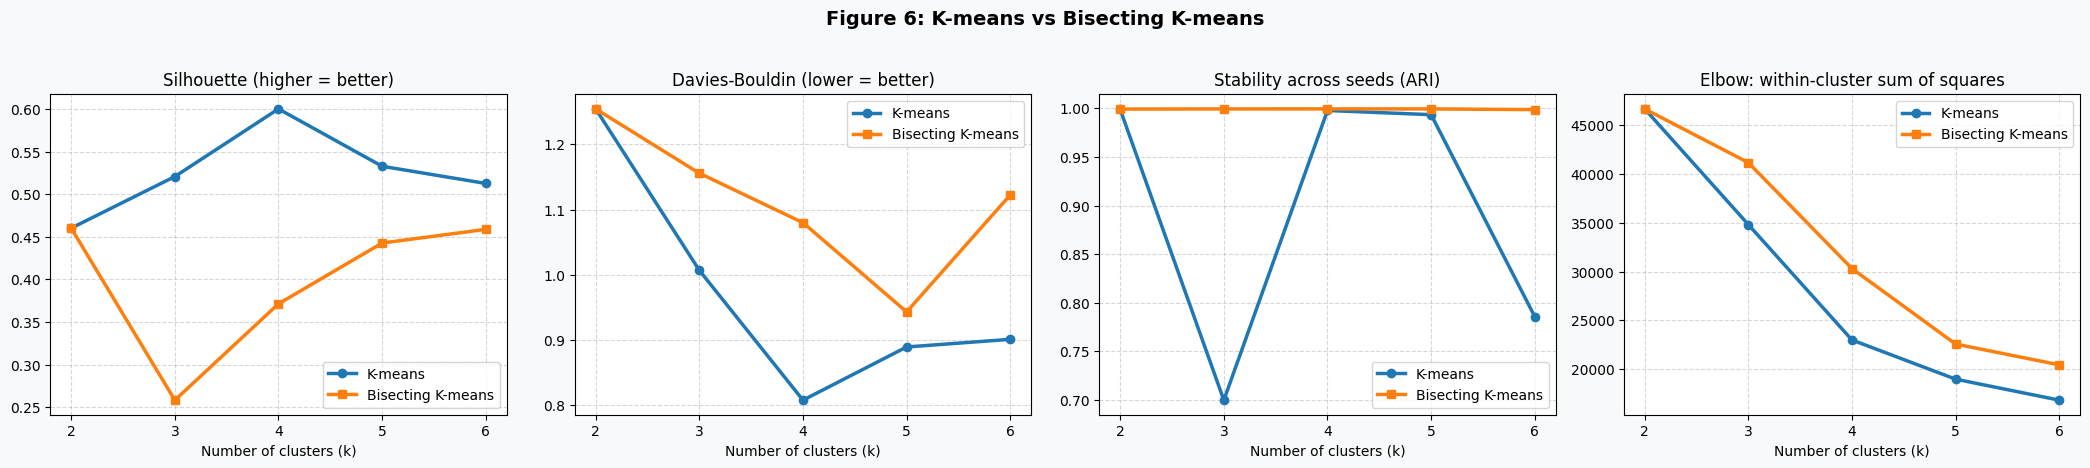

In [38]:
# Task 8.2: (Cell 48): Figure 6 - K-means vs Bisecting K-means for every k
plots = [("silhouette", "Silhouette (higher = better)"),
         ("davies_bouldin", "Davies-Bouldin (lower = better)"),
         ("stability_ari", "Stability across seeds (ARI)"),
         ("cost", "Elbow: within-cluster sum of squares")]

fig, axes = plt.subplots(1, 4, figsize=(21, 4.5), facecolor="#f8f9fa")
for ax, (metric, title) in zip(axes, plots):
    kmeans_rows = Summary[Summary["algorithm"] == "kmeans"]
    bkm_rows = Summary[Summary["algorithm"] == "bisecting_kmeans"]
    ax.plot(kmeans_rows["k"], kmeans_rows[metric], marker="o", color="#1f77b4", linewidth=2.5, label="K-means")
    ax.plot(bkm_rows["k"], bkm_rows[metric], marker="s", color="#ff7f0e", linewidth=2.5, label="Bisecting K-means")
    ax.set_title(title)
    ax.set_xlabel("Number of clusters (k)")
    ax.set_xticks(K_VALUES)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend()

plt.suptitle("Figure 6: K-means vs Bisecting K-means", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig("results/figures/fig6_algorithm_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

In [39]:
# Task 8.3: (Cell 49): Choose k for each algorithm with the rule
chosen_k = {}
for algorithm_name in ["kmeans", "bisecting_kmeans"]:
    rows = Summary[Summary["algorithm"] == algorithm_name]
    # rule: stable (ARI >= 0.80) and no tiny cluster (>= 2% of fields)
    good = rows[(rows["stability_ari"] >= 0.80) & (rows["min_cluster_share"] >= 0.02)]
    if len(good) == 0:
        print(f"{algorithm_name}: no k passed the rule, so the best silhouette overall is used")
        good = rows
    # among the good ones, the highest silhouette wins
    best_row = good.sort_values("silhouette", ascending=False).iloc[0]
    chosen_k[algorithm_name] = int(best_row["k"])

print(f"Chosen k: {chosen_k}")

# the main comparison table for Chapter 5
Comparison = pd.concat([Summary[(Summary["algorithm"] == a) & (Summary["k"] == k)] for a, k in chosen_k.items()])
Comparison[["algorithm", "k", "silhouette", "davies_bouldin", "stability_ari", "min_cluster_share", "nmi_crop_group"]].round(4)

Chosen k: {'kmeans': 4, 'bisecting_kmeans': 2}


,algorithm,k,silhouette,davies_bouldin,stability_ari,min_cluster_share,nmi_crop_group
7,kmeans,4,0.6001,0.8081,0.9979,0.0463,0.3216
0,bisecting_kmeans,2,0.4602,1.2542,0.9994,0.4663,0.2509


## Task 9: Final clusters and labels
Each algorithm is trained once more with its selected k and seed 11. For K-means, seed 11 gave the lowest
within-cluster sum of squares at k = 4; for Bisecting K-means, the three seeds gave almost identical clusters
(ARI 0.999). Each cluster then receives a **low / medium / high** label for three indicators:
* **Pesticide use:** the cluster's mean treatment frequency is compared with the national average for all farmland,
  3.99 BI/ha (Miljøstyrelsen, 2026): low below 0.5 × the average (< 2.0), high above 1.5 × the average (> 6.0),
  otherwise medium.
* **Vegetation vigour** (peak NDVI): low if the cluster mean is below the 33rd percentile of all fields, high if
  above the 67th percentile, otherwise medium.
* **Moisture stress** (NDWI at peak): the same percentile rule, reversed, because lower NDWI indicates drier
  vegetation. A cluster mean below the 33rd percentile is labelled high stress.

The labels are indicative only. They are derived from crop-group averages and satellite proxies, not from
measurements on individual fields.

In [40]:
# Task 9.1: (Cell 51): Train the final models with the chosen k
# one row per field, sorted by field ID (the same order as the predictions)
Final = CleanPd.sort_values("field_id").reset_index(drop=True)

# K-means with its chosen k
kmeans_final = KMeans(featuresCol="features", k=chosen_k["kmeans"], seed=SEEDS[0], maxIter=50).fit(ModelData)
kmeans_clusters = kmeans_final.transform(ModelData).select("field_id", "prediction").toPandas().sort_values("field_id")
Final["cluster_kmeans"] = kmeans_clusters["prediction"].to_numpy()

# Bisecting K-means with its chosen k
bkm_final = BisectingKMeans(featuresCol="features", k=chosen_k["bisecting_kmeans"], seed=SEEDS[0], maxIter=50).fit(ModelData)
bkm_clusters = bkm_final.transform(ModelData).select("field_id", "prediction").toPandas().sort_values("field_id")
Final["cluster_bisecting_kmeans"] = bkm_clusters["prediction"].to_numpy()

print(f"Fields per K-means cluster: {Final['cluster_kmeans'].value_counts().sort_index().to_dict()}")
print(f"Fields per Bisecting K-means cluster: {Final['cluster_bisecting_kmeans'].value_counts().sort_index().to_dict()}")

Fields per K-means cluster: {0: 2964, 1: 5980, 2: 3941, 3: 625}
Fields per Bisecting K-means cluster: {0: 6299, 1: 7211}


In [41]:
# Task 9.2: (Cell 52): Functions that turn a number into low / medium / high
# pesticide: compared with the Danish average (3.99 BI/ha)
def pesticide_level(bi):
    if bi < 0.5 * NATIONAL_AVERAGE_BI:
        return "low"
    if bi > 1.5 * NATIONAL_AVERAGE_BI:
        return "high"
    return "medium"

# any value: compared with all fields (lowest third / middle third / highest third)
def percentile_level(value, all_values):
    if value < np.percentile(all_values, 33.3):
        return "low"
    if value > np.percentile(all_values, 66.7):
        return "high"
    return "medium"

# moisture stress: lower NDWI = drier leaves = MORE stress, so the scale is turned around
def stress_level(ndwi):
    level = percentile_level(ndwi, Final["ndwi_at_peak"])
    return {"low": "high", "medium": "medium", "high": "low"}[level]

# the three most common crop groups in a cluster, for example "potatoes 100%"
def top_three_crops(crop_groups):
    shares = crop_groups.value_counts(normalize=True).head(3)
    return ", ".join(f"{group} {share:.0%}" for group, share in shares.items())

In [42]:
# Task 9.3: (Cell 53): Cluster profiles with labels
AllProfiles = []
for algorithm_name in ["kmeans", "bisecting_kmeans"]:
    cluster_column = "cluster_" + algorithm_name
    groups = Final.groupby(cluster_column)

    # average of every feature per cluster (ndwi_min is kept only for comparison)
    Profile = groups[FEATURES + ["ndwi_min"]].mean()
    Profile["n_fields"] = groups.size()
    Profile["share_of_fields"] = Profile["n_fields"] / len(Final)
    Profile["area_ha"] = groups["area_ha"].sum()
    Profile["top_crop_groups"] = groups["crop_group"].agg(top_three_crops)

    # the three labels
    Profile["pesticide_label"] = Profile["bi_per_ha"].apply(pesticide_level)
    Profile["moisture_stress_label"] = Profile["ndwi_at_peak"].apply(stress_level)
    Profile["vigour_label"] = Profile["ndvi_peak"].apply(lambda value: percentile_level(value, Final["ndvi_peak"]))

    Profile = Profile.reset_index().rename(columns={cluster_column: "cluster"})
    Profile.insert(0, "algorithm", algorithm_name)
    AllProfiles.append(Profile)

    # copy the labels onto every field (for the app)
    for label in ["pesticide_label", "moisture_stress_label", "vigour_label"]:
        Final[label + "_" + algorithm_name] = Final[cluster_column].map(Profile.set_index("cluster")[label])

Profiles = pd.concat(AllProfiles, ignore_index=True)
Profiles[["algorithm", "cluster", "n_fields", "bi_per_ha", "ndwi_at_peak", "ndvi_peak",
          "pesticide_label", "moisture_stress_label", "vigour_label", "top_crop_groups"]].round(3)

,algorithm,cluster,n_fields,bi_per_ha,ndwi_at_peak,ndvi_peak,pesticide_label,moisture_stress_label,vigour_label,top_crop_groups
0,kmeans,0,2964,2.027,0.300,0.766,medium,high,low,"spring_cereals 27%, winter_cereals 22%, maize 18%"
1,kmeans,1,5980,0.973,0.434,0.870,low,medium,medium,"grass_clover_rotation 35%, permanent_grass 34%..."
2,kmeans,2,3941,2.616,0.482,0.876,medium,low,medium,"spring_cereals 69%, maize 17%, winter_cereals 7%"
3,kmeans,3,625,22.820,0.450,0.884,high,medium,high,potatoes 100%
4,bisecting_kmeans,0,6299,4.156,0.421,0.838,medium,medium,medium,"spring_cereals 54%, maize 18%, winter_cereals 14%"
5,bisecting_kmeans,1,7211,1.418,0.418,0.859,low,medium,medium,"permanent_grass 34%, grass_clover_rotation 33%..."


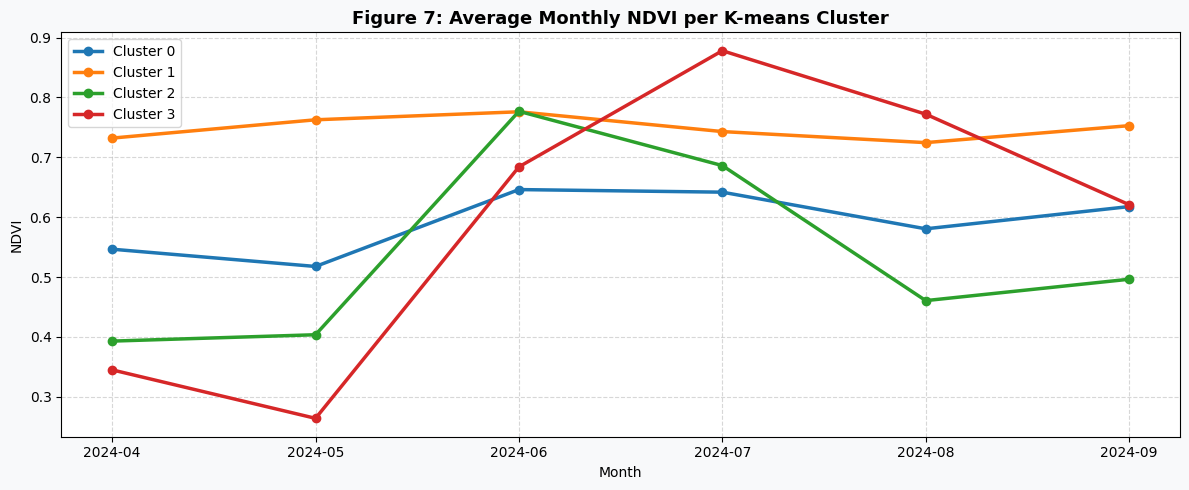

In [43]:
# Task 9.4: (Cell 54): Figure 7 - average NDVI per month for each K-means cluster
plt.figure(figsize=(12, 5), facecolor="#f8f9fa")
for cluster in sorted(Final["cluster_kmeans"].unique()):
    monthly_ndvi = Final[Final["cluster_kmeans"] == cluster][ndvi_months].mean()
    plt.plot(MONTHS, monthly_ndvi.values, marker="o", linewidth=2.5, label=f"Cluster {cluster}")

plt.title("Figure 7: Average Monthly NDVI per K-means Cluster", fontsize=13, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("NDVI")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("results/figures/fig7_cluster_ndvi.png", dpi=200)
plt.show()

## Task 10: Sensitivity check without the pesticide feature
Because every field in a crop group has the same pesticide value, this feature may push the clusters towards the
crop groups. To test this, both algorithms are run again with the satellite features only, using the same k and
seed, and the overlap with crop groups (NMI) is compared with the full model. A clear drop in NMI indicates that
the pesticide feature strongly shapes the clusters.

In [44]:
## Task 10.1: (Cell 56): Cluster again with the satellite features only
SatelliteOnly = [feature for feature in CLUSTER_FEATURES if feature in SATELLITE_FEATURES]
print(f"Satellite features used: {SatelliteOnly}")

# same steps as Task 6, without bi_per_ha
SatAssembled = VectorAssembler(inputCols=SatelliteOnly, outputCol="raw_features").transform(CleanData)
SatelliteModelData = scaler.fit(SatAssembled).transform(SatAssembled).select("field_id", "features")
SatelliteModelData = SatelliteModelData.orderBy("field_id").coalesce(1).cache()

Check = []
for algorithm_name, Algorithm in [("kmeans", KMeans), ("bisecting_kmeans", BisectingKMeans)]:
    k = chosen_k[algorithm_name]
    model = Algorithm(featuresCol="features", k=k, seed=SEEDS[0], maxIter=50).fit(SatelliteModelData)
    sat_clusters = model.transform(SatelliteModelData).select("field_id", "prediction").toPandas().sort_values("field_id")
    Check.append({
        "algorithm": algorithm_name,
        "k": k,
        "NMI with crop group (all 5 features)": normalized_mutual_info_score(Final["crop_group"], Final["cluster_" + algorithm_name]),
        "NMI with crop group (satellite only)": normalized_mutual_info_score(Final["crop_group"], sat_clusters["prediction"]),
    })

pd.DataFrame(Check).round(4)

Satellite features used: ['ndvi_median', 'ndvi_peak', 'ndwi_median', 'ndwi_at_peak']


,algorithm,k,NMI with crop group (all 5 features),NMI with crop group (satellite only)
0,kmeans,4,0.3219,0.2127
1,bisecting_kmeans,2,0.2508,0.2273


## Task 11: Export for the Streamlit application
The final field clusters, cluster profiles, evaluation scores and selected settings are saved and packed into
`thesis_results.zip`. The Streamlit application runs locally rather than in Kaggle: the archive is extracted into
the application folder and started with `streamlit run app.py`. The application reads only these saved files,
so it does not require Spark.

In [45]:
# Task 11.1: (Cell 58): Save everything the app needs
# fields with their shapes and clusters (lat/lon for the map)
AppFields = Fields[["field_id", "geometry"]].merge(Final, on="field_id", how="inner")
AppFields["geometry"] = AppFields.simplify(5)
AppFields = gpd.GeoDataFrame(AppFields, geometry="geometry", crs="EPSG:25832").to_crs("EPSG:4326")
AppFields.to_parquet("data/processed/app_fields.parquet")

# cluster profiles, all scores and the chosen k
Profiles.round(4).to_csv("data/processed/cluster_profiles.csv", index=False, encoding="utf-8-sig")
Summary["feature_set"] = "full"
Summary.round(4).to_csv("results/step5_summary.csv", index=False)
ResultsTable.round(4).to_csv("results/all_runs.csv", index=False)

rule = "stability_ari >= 0.8 and min_cluster_share >= 0.02, then highest silhouette"
selected = {"full": {"kmeans": {"k": chosen_k["kmeans"], "rule": rule},
                     "bisecting_kmeans": {"k": chosen_k["bisecting_kmeans"], "rule": rule}}}
with open("results/step5_selected.json", "w") as file:
    json.dump(selected, file, indent=2)

print(f"Saved {len(AppFields)} fields for the app")

Saved 13510 fields for the app


In [46]:
# Task 11.2: (Cell 59): Pack the results into one zip file for download
# only the result folders are packed (never the folder the zip file itself is in)
import zipfile

with zipfile.ZipFile("thesis_results.zip", "w", zipfile.ZIP_DEFLATED) as zip_file:
    for folder in ["results", "data/processed"]:
        for root, _, files in os.walk(folder):
            for name in files:
                zip_file.write(os.path.join(root, name))
    zip_file.write(SATELLITE_FILE)          #  satellite download

print(f"thesis_results.zip: {os.path.getsize('thesis_results.zip') / 1e6:.1f} MB")

thesis_results.zip: 7.7 MB
